# Exercise 1 (10 points)

In this exercise, we will practice how to properly format code. You are given a simple but poorly formatted Python code snippet that performs some common data science tasks (loading data, cleaning, and basic analysis). Your task is to refactor the code to improve readability, organization, and adhere to Python's PEP8 formatting guidelines.

```
import pandas as pd 
import numpy as np

data=pd.read_csv('credit_risk_dataset.csv')
# drop rows with missing values
data=data.dropna()

cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
def converting_datatypes(df, cat_cols, df_train=False):
    
    for col in cat_cols:
        df[col] = df[col].astype('category')
    
    df['person_age'] = df['person_age'].astype('int32')
    df['cb_person_cred_hist_length'] = df['cb_person_cred_hist_length'].astype('int32') 
    
    if df_train==True:

        df['loan_status'] = df['loan_status'].astype('int8')
        
    return df
        
data = converting_datatypes(data, cat_cols, df_train=True)

X=data.drop('loan_status',axis=1)
y=data['loan_status']

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

from sklearn.ensemble import HistGradientBoostingClassifier
hg=HistGradientBoostingClassifier(n_estimators=100, categorical_features='from_dtype')
hg.fit(X_train,y_train)
print('Train accuracy:',hg.score(X_train,y_train))
print('Test accuracy:',hg.score(X_test,y_test))
```

# Exercise 2

In this exercise, we will practice data visualiation with the `credit_risk_dataset.csv` data file.

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`.

In [6]:
import pandas as pd  
import matplotlib.pyplot as plt 
import seaborn as sns 



### Exercise 2(b) (2 points)

Read the `credit_risk_dataset.csv` data file and create a data frame called `credit`.

In [7]:
credit = pd.read_csv("credit_risk_dataset.csv")

print(credit) 


       person_age  person_income person_home_ownership  person_emp_length  \
0              22          59000                  RENT              123.0   
1              21           9600                   OWN                5.0   
2              25           9600              MORTGAGE                1.0   
3              23          65500                  RENT                4.0   
4              24          54400                  RENT                8.0   
...           ...            ...                   ...                ...   
32576          57          53000              MORTGAGE                1.0   
32577          54         120000              MORTGAGE                4.0   
32578          65          76000                  RENT                3.0   
32579          56         150000              MORTGAGE                5.0   
32580          66          42000                  RENT                2.0   

           loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status  \

### Exercise 2(c) (4 points)

Create a histogram of `person_income`. Color the distribution based on `loan_status`. Comment on the shape of the distributions.

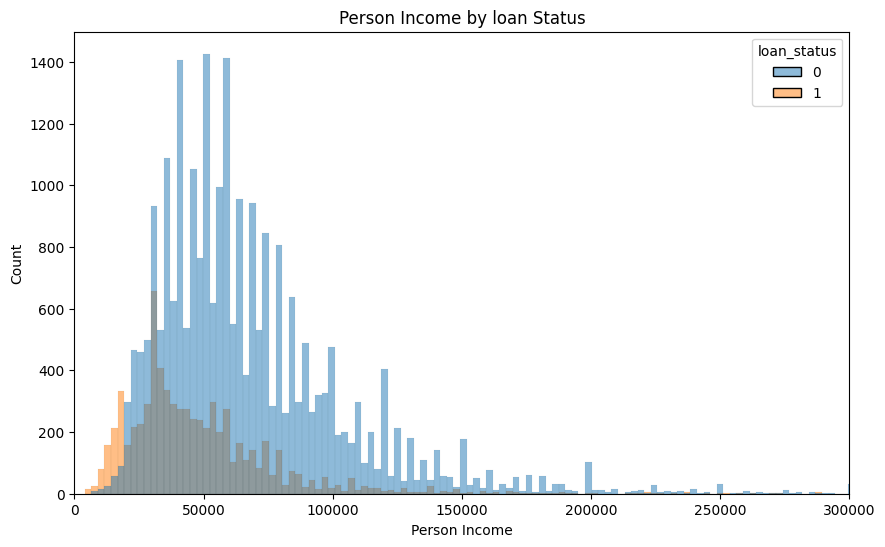

In [11]:
plt.figure(figsize=(10, 6)) 

sns.histplot(
    data=credit,
    x="person_income",
    hue="loan_status"
) 

plt.title("Person Income by loan Status")
plt.xlabel("Person Income") 
plt.ylabel("Count") 

plt.xlim(0, 300000)

plt.show()

### Exercise 2(d) (5 points)

Create a side-by-side boxplot of `loan_int_rate` based on `loan_grade`. Describe the chart.

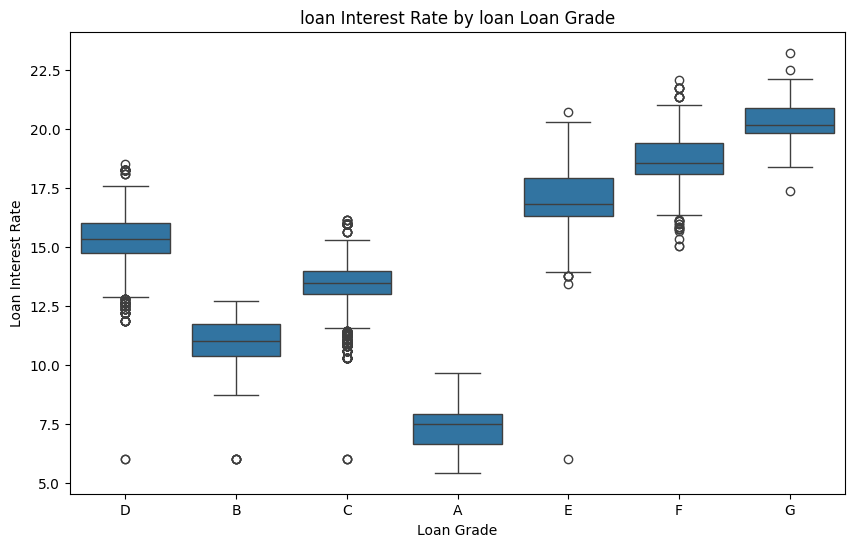

In [13]:
plt.figure(figsize=(10, 6)) 

sns.boxplot(
    data=credit, 
    x="loan_grade",
    y="loan_int_rate"
) 

plt.title("loan Interest Rate by loan Loan Grade") 
plt.xlabel("Loan Grade") 
plt.ylabel("Loan Interest Rate") 

plt.show()

### Exercise 2(e) (10 points)

Is there a realtionship between `person_home_ownership`, `loan_intent`, and `loan_status`? Create a heatmap that shows the average `loan_status` based on `person_home_ownership` and `loan_intent`. Describe the chart.

In [14]:
heatmap_data = credit.pivot_table(
    values="loan_status", 
    index="person_home_ownership", 
    columns="loan_intent",
    aggfunc="mean"
) 

heatmap_data 


loan_intent,DEBTCONSOLIDATION,EDUCATION,HOMEIMPROVEMENT,MEDICAL,PERSONAL,VENTURE
person_home_ownership,,,,,,
MORTGAGE,0.193772,0.082223,0.137277,0.215068,0.090598,0.046553
OTHER,0.470588,0.352941,0.250000,0.411765,0.444444,0.038462
OWN,0.388889,0.054924,0.106918,0.099078,0.062780,0.039440
RENT,0.357880,0.262115,0.433507,0.320700,0.312845,0.265993


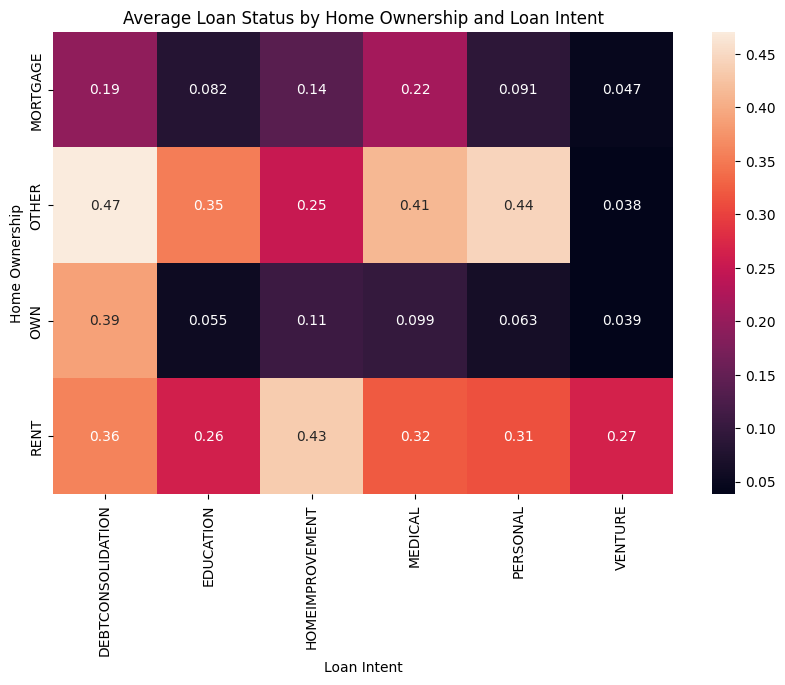

In [15]:
plt.figure(figsize=(10, 6)) 

sns.heatmap(
    heatmap_data, 
    annot=True 
) 

plt.title("Average Loan Status by Home Ownership and Loan Intent") 
plt.xlabel("Loan Intent") 
plt.ylabel("Home Ownership") 

plt.show()

The heatmap shows that average loan status varies depending on both home ownership and loan intent. The highest values appear for people in the other home ownership category, especially for debt consolidation, personal, and medical loans. Renters also show relatively high average loan status values across several loan intents. Mortgage and own categories generally have lower averages for most loan purposes. This sugguests that home owenership and loan intent may both be related to loan status. 

# Exercise 3 (10 points)

In this exercise, we will practice import formatting (Section 6.2 of Chapter 6).

### Exercise 3(a) (5 points)

The import block below grew organically and does not follow PEP8. Rewrite it so that:

- imports are grouped as (1) standard library, (2) third-party libraries, with a blank line between groups,
- imports are sorted alphabetically within each group (`import x` statements before `from x import y` statements),
- there is only one import per module line (for example, `import sys, os` must be split), and
- repeated imports from the same module are merged into a single line.


In [4]:
import time
from sklearn.metrics import accuracy_score

import sys, os
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, f1_score

In [16]:
import time 
import sys 
import os 
import numpy as np 
import pandas as pd  
import matplotlib.pyplot as plt 

from sklearn.ensemble import HistGradientBoostingClassifier 
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split 


### Exercise 3(b) (5 points)

Name two cases where reordering imports (for example, with `isort`) is **not** behavior-preserving. How can you tell `isort` to leave a line alone?